In [1]:
import numpy as np
import geopandas as gpd
import rasterio as rio
from rasterio.crs import CRS
from rasterio.features import rasterize
from affine import Affine
from pyproj import Proj, transform, Transformer
from matplotlib import pyplot as plt
import cartopy.crs as ccrs
import seaborn as sns
from pathlib import Path
from shapely.geometry import mapping

In [2]:
wgs84 = CRS.from_epsg(4326)
eckert4 = CRS.from_proj4("+proj=eck4 +lon_0=0 +x_0=0 +y_0=0 +datum=WGS84 +units=m")

In [3]:
transformer_ecket4 = Transformer.from_crs(wgs84, eckert4, always_xy=True)

In [4]:
x_north, y_north = transformer_ecket4.transform(0, 90)   # 输出可能是 (0, 8,622,000)
x_south, y_south = transformer_ecket4.transform(0, -90) # 输出可能是 (0, -8,622,000)
x_east, y_east = transformer_ecket4.transform(180, 0) 
x_west, y_east = transformer_ecket4.transform(-180, 0)

print(y_north)
print(y_south)
print(x_east)
print(x_west)
print('1km: ', x_east / 1e3, y_north / 1e3, 'deviations: ', ((x_east // 1e3) + 1) * 1e3 - x_east, ((y_north // 1e3) + 1) * 1e3 - y_north)
print('2km: ', x_east / 2e3, y_north / 2e3, 'deviations: ', ((x_east // 2e3) + 1) * 2e3 - x_east, ((y_north // 2e3) + 1) * 2e3 - y_north)
print('5km: ', x_east / 5e3, y_north / 5e3, 'deviations: ', ((x_east // 5e3) + 1) * 5e3 - x_east, ((y_north // 5e3) + 1) * 5e3 - y_north)
print('10km: ', x_east / 1e4, y_north / 1e4, 'deviations: ', ((x_east // 1e4) + 1) * 1e4 - x_east, ((y_north // 1e4) + 1) * 1e4 - y_north)
print('30km: ', x_east / 3e4, y_north / 3e4, 'deviations: ', ((x_east // 3e4) + 1) * 3e4 - x_east, ((y_north // 3e4) + 1) * 3e4 - y_north)
print('50km: ', x_east / 5e4, y_north / 5e4, 'deviations: ', ((x_east // 5e4) + 1) * 5e4 - x_east, ((y_north // 5e4) + 1) * 5e4 - y_north)
print('100km: ', x_east / 1e5, y_north / 1e5, 'deviations: ', ((x_east // 1e5) + 1) * 1e5 - x_east, ((y_north // 1e5) + 1) * 1e5 - y_north)

8460601.461471582
-8460601.461471582
16921202.922943164
-16921202.922943164
1km:  16921.202922943165 8460.601461471582 deviations:  797.0770568363369 398.5385284181684
2km:  8460.601461471582 4230.300730735791 deviations:  797.0770568363369 1398.5385284181684
5km:  3384.240584588633 1692.1202922943164 deviations:  3797.077056836337 4398.538528418168
10km:  1692.1202922943164 846.0601461471582 deviations:  8797.077056836337 9398.538528418168
30km:  564.0400974314388 282.0200487157194 deviations:  28797.077056836337 29398.53852841817
50km:  338.42405845886327 169.21202922943164 deviations:  28797.077056836337 39398.53852841817
100km:  169.21202922943164 84.60601461471582 deviations:  78797.07705683634 39398.53852841817


In [3]:
world_map = gpd.read_file(r'../data/gadm-world/world-map.shp')

In [6]:
world_map_eckert4 = world_map.to_crs("ESRI:54012")

In [4]:
world_map_cea = world_map.to_crs("EPSG:6933")

In [7]:
world_map_eckert4

,GID_0,COUNTRY,geometry
0,IRN,Iran,"MULTIPOLYGON (((5561606.523 3254895.679, 55616..."
1,BLM,Saint-Barthélemy,"MULTIPOLYGON (((-5790311.232 2332718.712, -579..."
2,UGA,Uganda,"POLYGON ((2811485.288 -194669.364, 2811461.46 ..."
3,SLE,Sierra Leone,"MULTIPOLYGON (((-1089022.845 920725.415, -1089..."
4,VCT,Saint Vincent and the Grenadines,"MULTIPOLYGON (((-5719892.159 1650401.974, -571..."
...,...,...,...
248,PHL,Philippines,"MULTIPOLYGON (((11766134.705 707327.318, 11766..."
249,MHL,Marshall Islands,"MULTIPOLYGON (((16148843.002 777615.227, 16148..."
250,MNP,Northern Mariana Islands,"MULTIPOLYGON (((13501497.471 1946365.655, 1350..."
251,IOT,British Indian Ocean Territory,"MULTIPOLYGON (((6788101.854 -952033.405, 67881..."


In [8]:
China_map = gpd.read_file("F:\china-cement-ccs-hotspots\data\China-maps\province.shp").to_crs("ESRI:54012")
China_map2 = gpd.read_file("F:\china-cement-ccs-hotspots\data\China-maps\province.shp").to_crs("EPSG:6933")

In [ ]:
fig = plt.figure(figsize=(10, 8), constrained_layout=True)

ax1 = plt.subplot(1, 1, 1)
world_map_eckert4.plot(lw=0.5, color='none', edgecolor='k', alpha=0.5, ax=ax1)

plt.show()

define the transforms for different resolutions 

In [9]:
wgs84 = CRS.from_epsg(4326)
eckert4 = CRS.from_proj4("+proj=eck4 +lon_0=0 +x_0=0 +y_0=0 +datum=WGS84 +units=m")

In [10]:
transformer_eckert4 = Transformer.from_crs(wgs84, eckert4, always_xy=True)

In [11]:
_, y_north = transformer_eckert4.transform(0, 90) 
x_east, _ = transformer_eckert4.transform(180, 0) 

shape_eckert4_1km = (int((y_north // 1e3 + 1) * 2), int((x_east // 1e3 + 1) * 2))
shape_eckert4_2km = (int((y_north // 2e3 + 1) * 2), int((x_east // 2e3 + 1) * 2))
shape_eckert4_5km = (int((y_north // 5e3 + 1) * 2), int((x_east // 5e3 + 1) * 2))
shape_eckert4_10km = (int((y_north // 1e4 + 1) * 2), int((x_east // 1e4 + 1) * 2))
shape_eckert4_30km = (int((y_north // 3e4 + 1) * 2), int((x_east // 3e4 + 1) * 2))
shape_eckert4_50km = (int((y_north // 5e4 + 1) * 2), int((x_east // 5e4 + 1) * 2))
shape_eckert4_100km = (int((y_north // 1e5 + 1) * 2), int((x_east // 1e5 + 1) * 2))

print(shape_eckert4_1km)
print(shape_eckert4_2km)
print(shape_eckert4_5km)
print(shape_eckert4_10km)
print(shape_eckert4_30km)
print(shape_eckert4_50km)
print(shape_eckert4_100km)

xmin_eckert4_1km, ymax_eckert4_1km = - (x_east // 1e3 + 1) * 1e3, (y_north // 1e3 + 1) * 1e3
xmin_eckert4_2km, ymax_eckert4_2km = - (x_east // 2e3 + 1) * 2e3, (y_north // 2e3 + 1) * 2e3
xmin_eckert4_5km, ymax_eckert4_5km = - (x_east // 5e3 + 1) * 5e3, (y_north // 5e3 + 1) * 5e3
xmin_eckert4_10km, ymax_eckert4_10km = - (x_east // 1e4 + 1) * 1e4, (y_north // 1e4 + 1) * 1e4 
xmin_eckert4_30km, ymax_eckert4_30km = - (x_east // 3e4 + 1) * 3e4, (y_north // 3e4 + 1) * 3e4 
xmin_eckert4_50km, ymax_eckert4_50km = - (x_east // 5e4 + 1) * 5e4, (y_north // 5e4 + 1) * 5e4
xmin_eckert4_100km, ymax_eckert4_100km = - (x_east // 1e5 + 1) * 1e5, (y_north // 1e5 + 1) * 1e5 

transform_eckert4_1km = Affine(1e3, 0, xmin_eckert4_1km, 0, -1e3, ymax_eckert4_1km)
transform_eckert4_2km = Affine(2e3, 0, xmin_eckert4_2km, 0, -2e3, ymax_eckert4_2km)
transform_eckert4_5km = Affine(5e3, 0, xmin_eckert4_5km, 0, -5e3, ymax_eckert4_5km)
transform_eckert4_10km = Affine(1e4, 0, xmin_eckert4_10km, 0, -1e4, ymax_eckert4_10km)
transform_eckert4_30km = Affine(3e4, 0, xmin_eckert4_30km, 0, -3e4, ymax_eckert4_30km)
transform_eckert4_50km = Affine(5e4, 0, xmin_eckert4_50km, 0, -5e4, ymax_eckert4_50km)
transform_eckert4_100km = Affine(1e5, 0, xmin_eckert4_100km, 0, -1e5, ymax_eckert4_100km)


print(transform_eckert4_1km)
print(transform_eckert4_2km)
print(transform_eckert4_5km)
print(transform_eckert4_10km)
print(transform_eckert4_30km)
print(transform_eckert4_50km)
print(transform_eckert4_100km)

(16922, 33844)
(8462, 16922)
(3386, 6770)
(1694, 3386)
(566, 1130)
(340, 678)
(170, 340)
| 1000.00, 0.00,-16922000.00|
| 0.00,-1000.00, 8461000.00|
| 0.00, 0.00, 1.00|
| 2000.00, 0.00,-16922000.00|
| 0.00,-2000.00, 8462000.00|
| 0.00, 0.00, 1.00|
| 5000.00, 0.00,-16925000.00|
| 0.00,-5000.00, 8465000.00|
| 0.00, 0.00, 1.00|
| 10000.00, 0.00,-16930000.00|
| 0.00,-10000.00, 8470000.00|
| 0.00, 0.00, 1.00|
| 30000.00, 0.00,-16950000.00|
| 0.00,-30000.00, 8490000.00|
| 0.00, 0.00, 1.00|
| 50000.00, 0.00,-16950000.00|
| 0.00,-50000.00, 8500000.00|
| 0.00, 0.00, 1.00|
| 100000.00, 0.00,-17000000.00|
| 0.00,-100000.00, 8500000.00|
| 0.00, 0.00, 1.00|


In [12]:
country_shapes_eckert4_ = [(a_shape, a_value) for a_shape, a_value in zip(world_map_eckert4.geometry, [i for i in range(1, 254)])]

In [6]:
country_shapes_cea_ = [(a_shape, a_value) for a_shape, a_value in zip(world_map_cea.geometry, [i for i in range(1, 254)])]

In [19]:
hk_geom = China_map.loc[China_map['省'] == '香港特别行政区', 'geometry'].iloc[0]
mac_geom = China_map.loc[China_map['省'] == '澳门特别行政区', 'geometry'].iloc[0]
HK_MAC = [(mapping(hk_geom), 254), (mapping(mac_geom), 255)]

In [9]:
hk_geom = China_map2.loc[China_map2['省'] == '香港特别行政区', 'geometry'].iloc[0]
mac_geom = China_map2.loc[China_map2['省'] == '澳门特别行政区', 'geometry'].iloc[0]
HK_MAC = [(mapping(hk_geom), 254), (mapping(mac_geom), 255)]

In [22]:
country_shapes_eckert4 = country_shapes_eckert4_ + HK_MAC

In [10]:
country_shapes_cea = country_shapes_cea_ + HK_MAC

In [23]:
country_raster_eckert4_1km = rasterize(
    shapes=country_shapes_eckert4, 
    out_shape=shape_eckert4_1km, 
    fill=0, 
    transform=transform_eckert4_1km,
    dtype=np.uint8)

In [11]:
src = rio.open(r'..\data\Global 7-land-types LULC projection dataset under SSPs-RCPs\global_LULC_2015.tif')

In [12]:
src.shape

(13374, 34736)

In [13]:
country_raster_cea_1km = rasterize(
    shapes=country_shapes_cea, 
    out_shape=src.shape, 
    fill=0, 
    transform=src.transform,
    dtype=np.uint8)

In [14]:
country_raster_cea_1km

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(13374, 34736), dtype=uint8)

In [17]:
with rio.open(
    '../results/country-rasters/country-raster-cea-1km.tif',
    'w',
    driver='GTiff',
    height=country_raster_cea_1km.shape[0],
    width=country_raster_cea_1km.shape[1],
    count=1,
    dtype=country_raster_cea_1km.dtype, 
    crs=src.crs,
    transform=src.transform,
    compress='lzw',
) as dst:
    dst.write(country_raster_cea_1km, 1)

In [26]:
country_raster_eckert4_2km = rasterize(
    shapes=country_shapes_eckert4, 
    out_shape=shape_eckert4_2km, 
    fill=0, 
    transform=transform_eckert4_2km,
    dtype=np.uint8)

In [27]:
country_raster_eckert4_5km = rasterize(
    shapes=country_shapes_eckert4, 
    out_shape=shape_eckert4_5km, 
    fill=0, 
    transform=transform_eckert4_5km,
    dtype=np.uint8)

In [28]:
country_raster_eckert4_10km = rasterize(
    shapes=country_shapes_eckert4, 
    out_shape=shape_eckert4_10km, 
    fill=0, 
    transform=transform_eckert4_10km,
    dtype=np.uint8)

In [29]:
country_raster_eckert4_30km = rasterize(
    shapes=country_shapes_eckert4, 
    out_shape=shape_eckert4_30km, 
    fill=0, 
    transform=transform_eckert4_30km,
    dtype=np.uint8)

In [30]:
country_raster_eckert4_50km = rasterize(
    shapes=country_shapes_eckert4, 
    out_shape=shape_eckert4_50km, 
    fill=0, 
    transform=transform_eckert4_50km,
    dtype=np.uint8)

In [31]:
country_raster_eckert4_100km = rasterize(
    shapes=country_shapes_eckert4, 
    out_shape=shape_eckert4_100km, 
    fill=0, 
    transform=transform_eckert4_100km,
    dtype=np.uint8)

display 

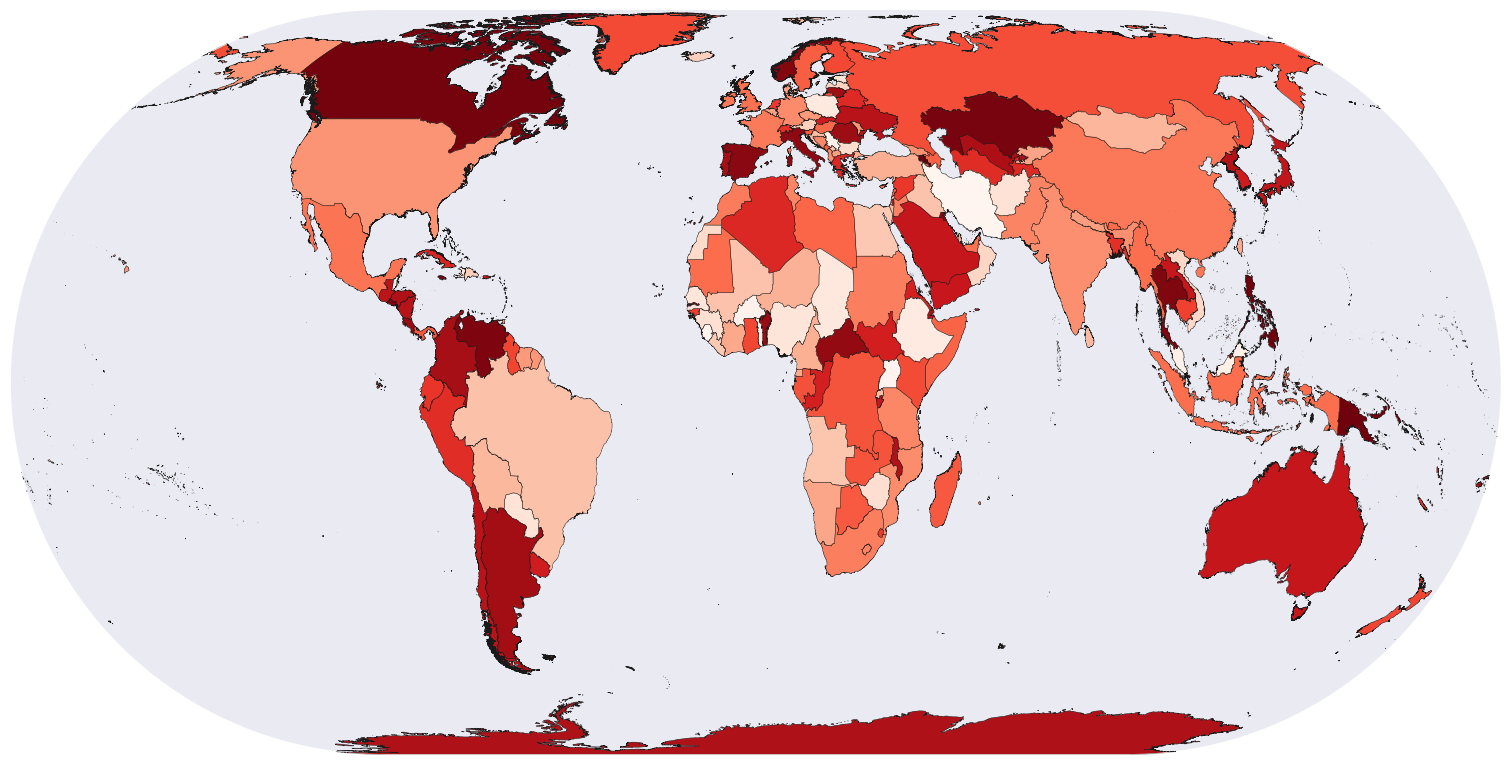

In [103]:
sns.set_theme(style="darkgrid")

fig = plt.figure(figsize=(15, 8), constrained_layout=True)
ax1 = plt.subplot(111, projection=ccrs.EckertIV())
ax1.imshow(np.where(country_raster_eckert4_1km == 0, np.nan, country_raster_eckert4_1km), cmap='Reds', origin='upper', extent=[xmin_eckert4_1km, -xmin_eckert4_1km, -ymax_eckert4_1km, ymax_eckert4_1km], zorder=0)
world_map_eckert4.plot(color='none', edgecolor='k', lw=0.25, ax=ax1, zorder=10)

plt.show()

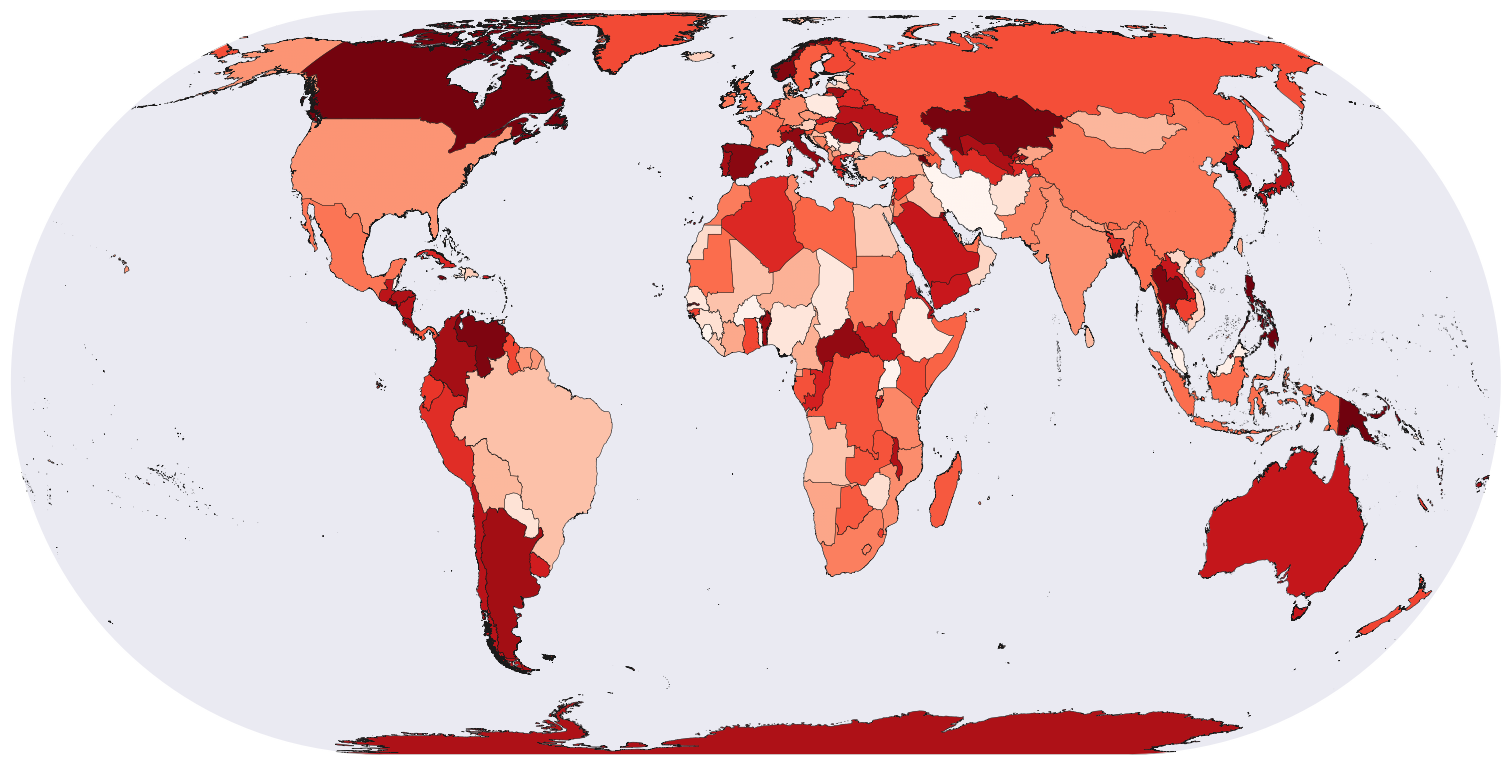

In [15]:
sns.set_theme(style="darkgrid")

fig = plt.figure(figsize=(15, 8), constrained_layout=True)
ax1 = plt.subplot(111, projection=ccrs.EckertIV())
ax1.imshow(np.where(country_raster_eckert4_2km == 0, np.nan, country_raster_eckert4_2km), cmap='Reds', origin='upper', extent=[xmin_eckert4_2km, -xmin_eckert4_2km, -ymax_eckert4_2km, ymax_eckert4_2km], zorder=0)
world_map_eckert4.plot(color='none', edgecolor='k', lw=0.25, ax=ax1, zorder=10)

plt.show()

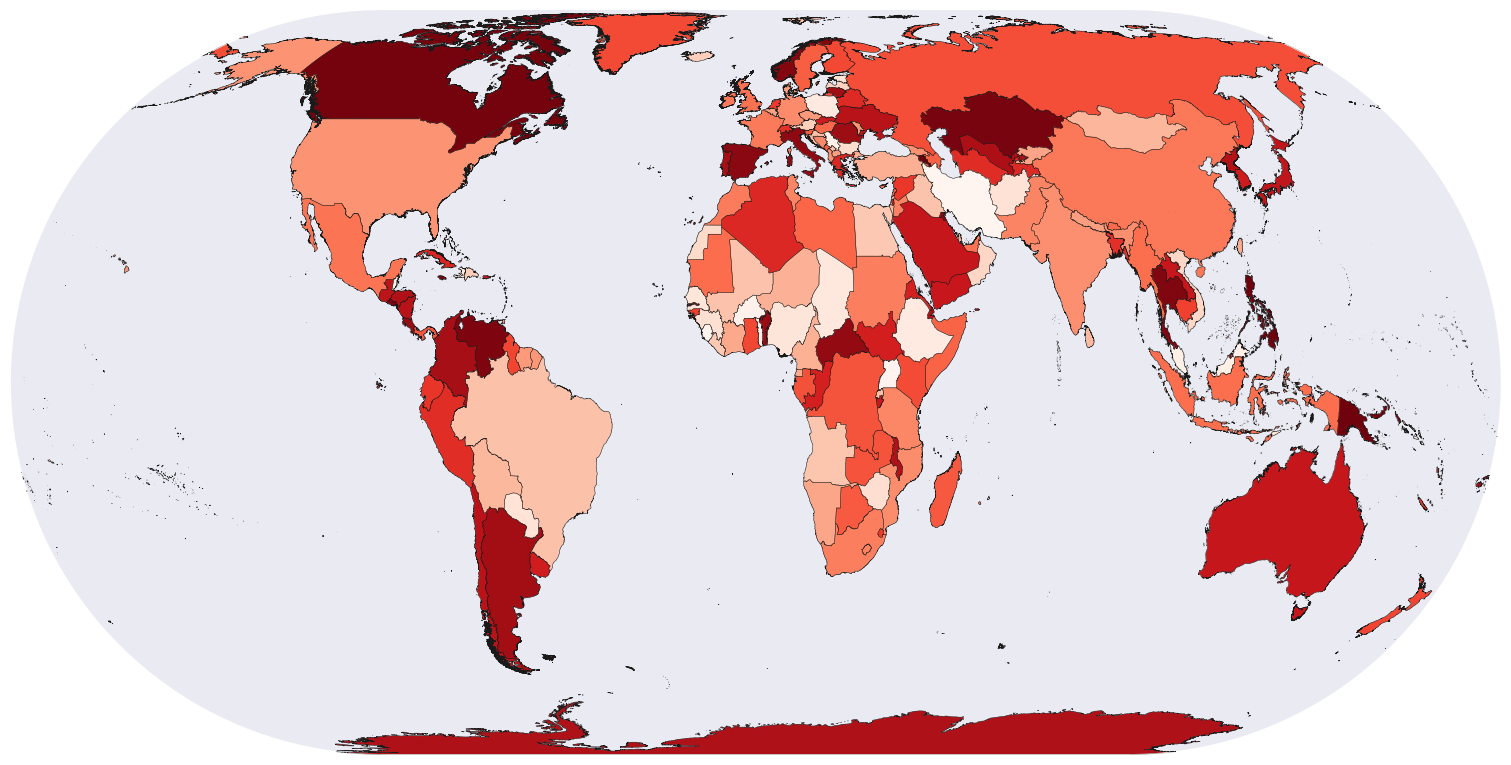

In [14]:
sns.set_theme(style="darkgrid")

fig = plt.figure(figsize=(15, 8), constrained_layout=True)
ax1 = plt.subplot(111, projection=ccrs.EckertIV())
ax1.imshow(np.where(country_raster_eckert4_5km == 0, np.nan, country_raster_eckert4_5km), cmap='Reds', origin='upper', extent=[xmin_eckert4_5km, -xmin_eckert4_5km, -ymax_eckert4_5km, ymax_eckert4_5km], zorder=0)
world_map_eckert4.plot(color='none', edgecolor='k', lw=0.25, ax=ax1, zorder=10)

plt.show()

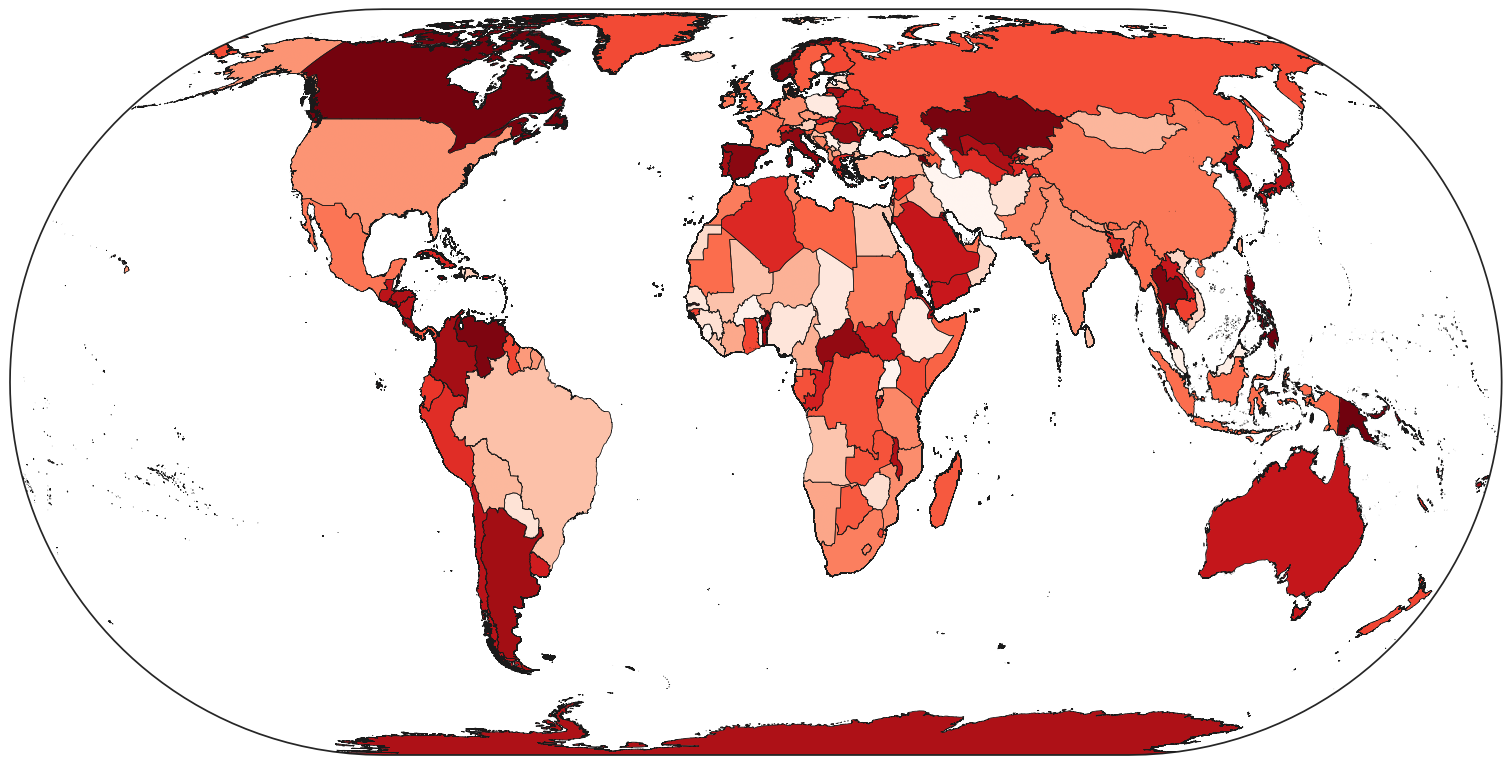

In [102]:
sns.set_theme(style="white")

fig = plt.figure(figsize=(15, 8), constrained_layout=True)
ax1 = plt.subplot(111, projection=ccrs.EckertIV())
ax1.imshow(np.where(country_raster_eckert4_10km == 0, np.nan, country_raster_eckert4_10km), cmap='Reds', origin='upper', extent=[xmin_eckert4_10km, -xmin_eckert4_10km, -ymax_eckert4_10km, ymax_eckert4_10km], zorder=0)
world_map_eckert4.plot(color='none', edgecolor='k', lw=0.5, ax=ax1, zorder=10)

plt.show()

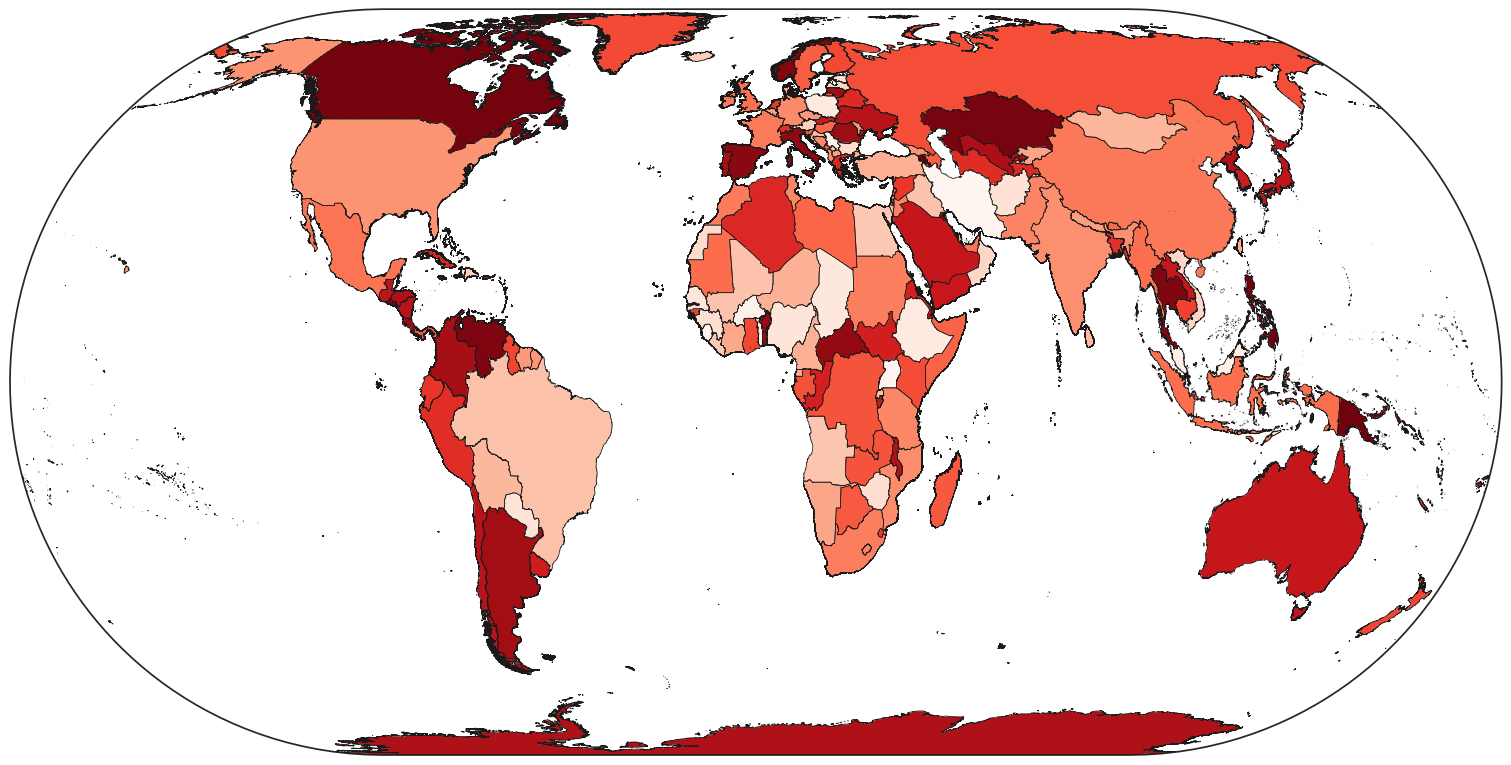

In [104]:
sns.set_theme(style="white")

fig = plt.figure(figsize=(15, 8), constrained_layout=True)
ax1 = plt.subplot(111, projection=ccrs.EckertIV())
ax1.imshow(np.where(country_raster_eckert4_30km == 0, np.nan, country_raster_eckert4_30km), cmap='Reds', origin='upper', extent=[xmin_eckert4_30km, -xmin_eckert4_30km, -ymax_eckert4_30km, ymax_eckert4_30km], zorder=0)
world_map_eckert4.plot(color='none', edgecolor='k', lw=0.5, ax=ax1, zorder=10)

plt.show()

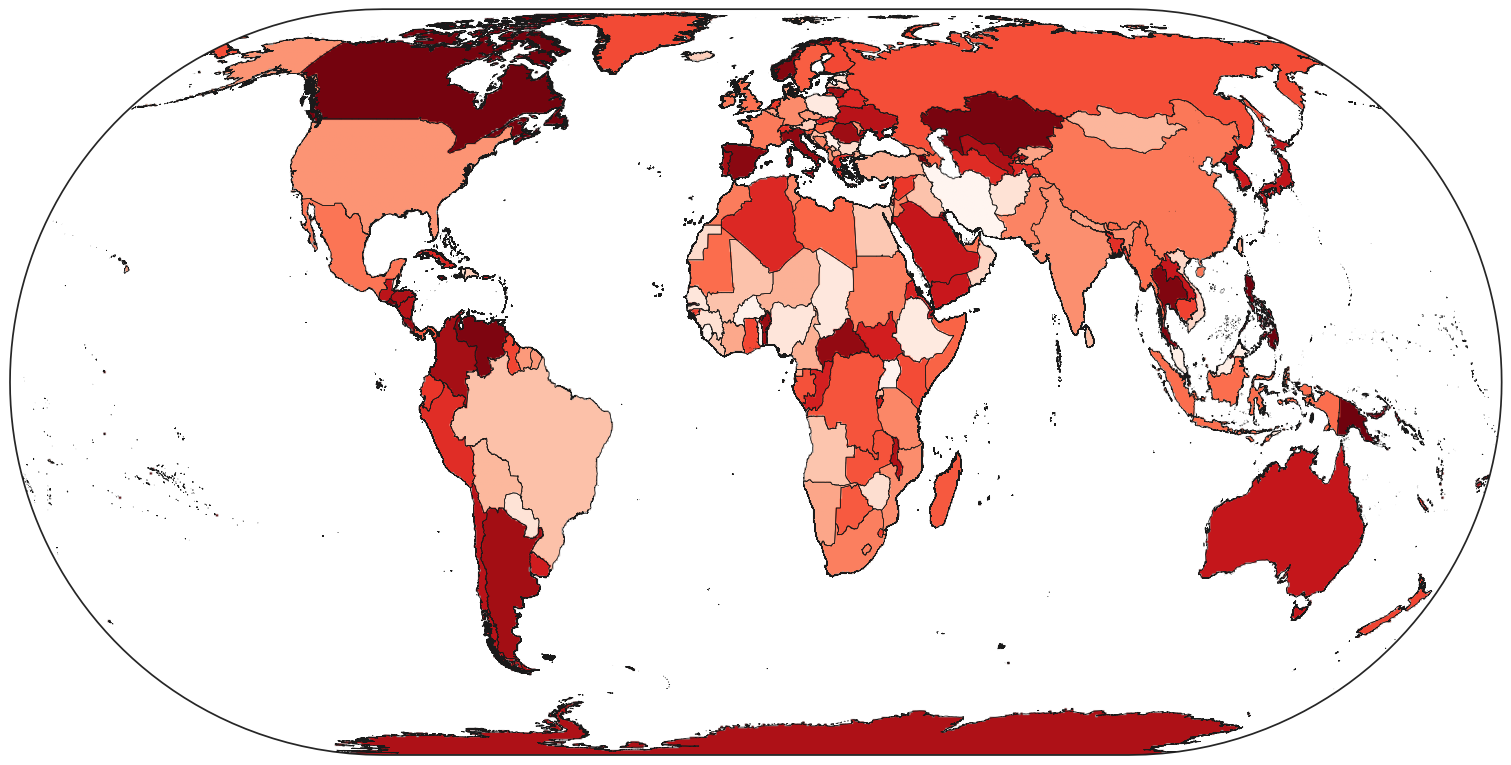

In [105]:
sns.set_theme(style="white")

fig = plt.figure(figsize=(15, 8), constrained_layout=True)
ax1 = plt.subplot(111, projection=ccrs.EckertIV())
ax1.imshow(np.where(country_raster_eckert4_50km == 0, np.nan, country_raster_eckert4_50km), cmap='Reds', origin='upper', extent=[xmin_eckert4_50km, -xmin_eckert4_50km, -ymax_eckert4_50km, ymax_eckert4_50km], zorder=0)
world_map_eckert4.plot(color='none', edgecolor='k', lw=0.5, ax=ax1, zorder=10)

plt.show()

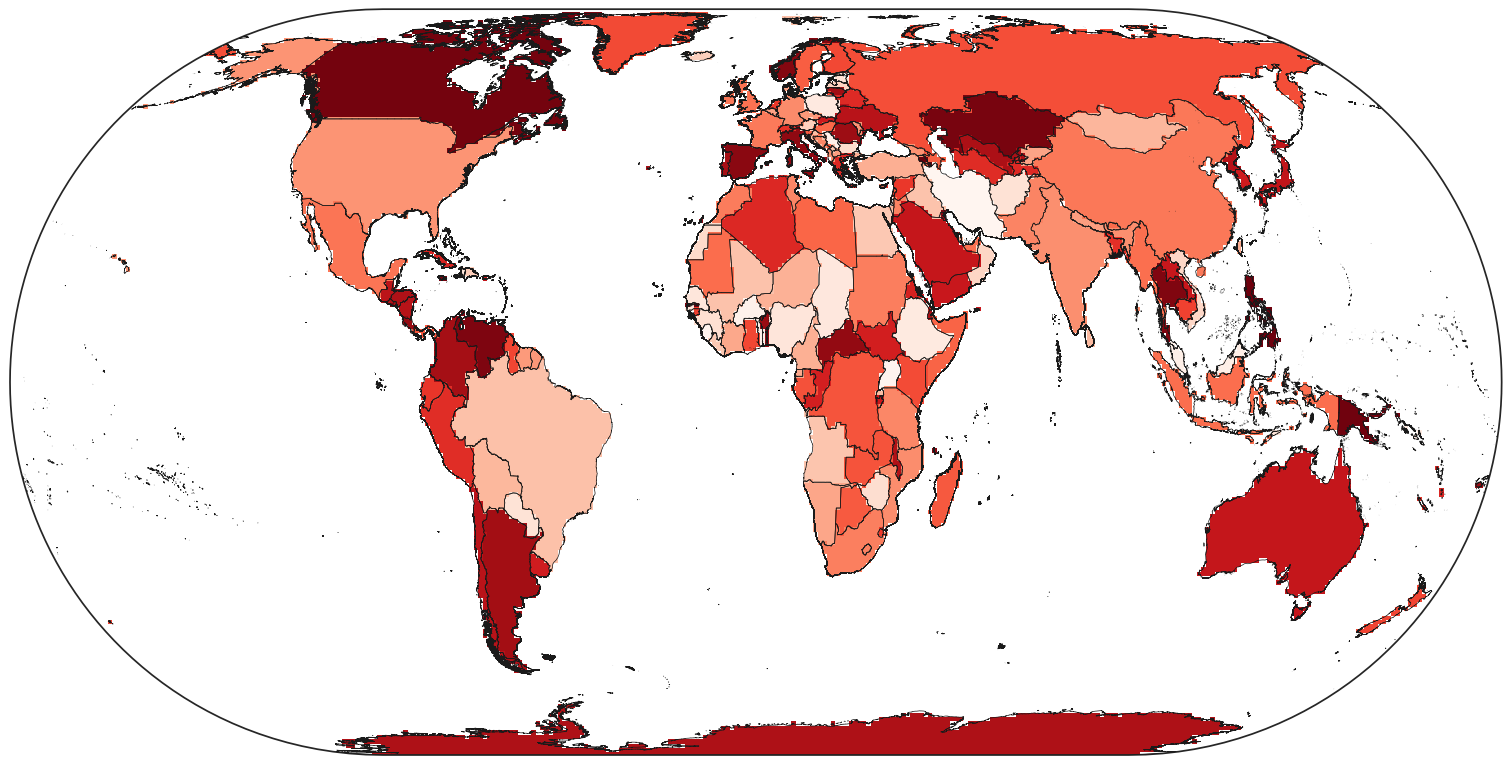

In [106]:
sns.set_theme(style="white")

fig = plt.figure(figsize=(15, 8), constrained_layout=True)
ax1 = plt.subplot(111, projection=ccrs.EckertIV())
ax1.imshow(np.where(country_raster_eckert4_100km == 0, np.nan, country_raster_eckert4_100km), cmap='Reds', origin='upper', extent=[xmin_eckert4_100km, -xmin_eckert4_100km, -ymax_eckert4_100km, ymax_eckert4_100km], zorder=0)
world_map_eckert4.plot(color='none', edgecolor='k', lw=0.5, ax=ax1, zorder=10)

plt.show()

output data

In [22]:
Path(r'../results/country-rasters').mkdir(parents=True, exist_ok=True)

In [25]:
with rio.open(
    r'../results/country-rasters/country-raster-eck4-1km.tif',
    'w',
    driver='GTiff',
    height=shape_eckert4_1km[0],
    width=shape_eckert4_1km[1],
    count=1,
    dtype=country_raster_eckert4_1km.dtype, 
    # crs=raster_1km_.crs,
    crs='ESRI:54012',
    transform=transform_eckert4_1km,
    compress='lzw',
) as dst:
    dst.write(country_raster_eckert4_1km, 1)

In [32]:
with rio.open(
    r'../results/country-rasters/country-raster-eck4-2km.tif',
    'w',
    driver='GTiff',
    height=shape_eckert4_2km[0],
    width=shape_eckert4_2km[1],
    count=1,
    dtype=country_raster_eckert4_2km.dtype, 
    crs='ESRI:54012',
    transform=transform_eckert4_2km,
    compress='lzw',
) as dst:
    dst.write(country_raster_eckert4_2km, 1)

In [33]:
with rio.open(
    r'../results/country-rasters/country-raster-eck4-5km.tif',
    'w',
    driver='GTiff',
    height=shape_eckert4_5km[0],
    width=shape_eckert4_5km[1],
    count=1,
    dtype=country_raster_eckert4_5km.dtype, 
    # crs=raster_5km_.crs,
    crs='ESRI:54012',
    transform=transform_eckert4_5km,
    compress='lzw',
) as dst:
    dst.write(country_raster_eckert4_5km, 1)

In [34]:
with rio.open(
    r'../results/country-rasters/country-raster-eck4-10km.tif',
    'w',
    driver='GTiff',
    height=shape_eckert4_10km[0],
    width=shape_eckert4_10km[1],
    count=1,
    dtype=country_raster_eckert4_10km.dtype, 
    # crs=raster_10km_.crs,
    crs='ESRI:54012',
    transform=transform_eckert4_10km,
    compress='lzw',
) as dst:
    dst.write(country_raster_eckert4_10km, 1)

In [35]:
with rio.open(
    r'../results/country-rasters/country-raster-eck4-30km.tif',
    'w',
    driver='GTiff',
    height=shape_eckert4_30km[0],
    width=shape_eckert4_30km[1],
    count=1,
    dtype=country_raster_eckert4_30km.dtype, 
    # crs=raster_30km_.crs,
    crs='ESRI:54012',
    transform=transform_eckert4_30km,
    compress='lzw',
) as dst:
    dst.write(country_raster_eckert4_30km, 1)

In [36]:
with rio.open(
    r'../results/country-rasters/country-raster-eck4-50km.tif',
    'w',
    driver='GTiff',
    height=shape_eckert4_50km[0],
    width=shape_eckert4_50km[1],
    count=1,
    dtype=country_raster_eckert4_50km.dtype, 
    # crs=raster_50km_.crs,
    crs='ESRI:54012',
    transform=transform_eckert4_50km,
    compress='lzw',
) as dst:
    dst.write(country_raster_eckert4_50km, 1)

In [37]:
with rio.open(
    r'../results/country-rasters/country-raster-eck4-100km.tif',
    'w',
    driver='GTiff',
    height=shape_eckert4_100km[0],
    width=shape_eckert4_100km[1],
    count=1,
    dtype=country_raster_eckert4_100km.dtype, 
    # crs=raster_100km_.crs,
    crs='ESRI:54012',
    transform=transform_eckert4_100km,
    compress='lzw',
) as dst:
    dst.write(country_raster_eckert4_100km, 1)